# Tutorial, Passo 5: Exemplos do GWpy

Este tutorial apresentará [GWpy](https://gwpy.github.io/), um pacote Python que oferece uma interface intuitiva e fácil de usar para dados comuns nos domínios do tempo e da frequência.
Também permite o acesso programático aos dados no [web site GWOSC](https://gwosc.org/).
Aqui, vamos nos concentrar apenas na leitura de dados do GWOSC.
Mais informações podem ser encontradas em [documentação do pacote](https://gwpy.github.io/docs/).

Esta etapa pressupõe familiaridade com alguns conceitos apresentados nos tutoriais anteriores, em particular sobre os indicadores de qualidade de dados introduzidos no [passo 3](<03 - Working with Data Quality.ipynb>).
Se você tiver dificuldade em entender alguns pontos, não hesite em voltar aos tutoriais anteriores.

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning</b></div>
   Remova o comentário da célula a seguir se estiver executando no Google Colab. 
   Se utilizar outros métodos de execução, isso não deve ser necessário.
</div>

In [1]:
#! wget http://gwosc.org/archive/data/O3b_4KHZ_R1/1263534080/H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5
#! pip install -q 'gwpy==3.0.13'

## Verificando a instalação

Vamos verificar se o GWpy está instalado corretamente no seu ambiente.

In [1]:
# Se você importar o GWpy sem essas linhas, poderá ver alguns avisos relacionados ao pacote LAL.
# Esses avisos são inofensivos, por isso usamos essas linhas para ocultá-los.
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

# Now import gwpy
import gwpy
print(gwpy.__version__)

3.0.13


## Lendo dados

[GWpy](https://gwpy.github.io/) fornece uma API de alto nível para ler arquivos GWOSC.
Isso é feito através da classe [TimeSeries](https://gwpy.github.io/docs/stable/timeseries/) e a classe-método [read](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.TimeSeries/#gwpy.timeseries.TimeSeries.read).

Vamos ler nossos dados:

In [2]:
from gwpy.timeseries import TimeSeries

filename = 'H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5'

# Note the format argument (see doc)
data = TimeSeries.read(filename, format="hdf5.gwosc")
print(data)

/home/rlisboa/.conda/envs/introduction_gwosc_data/lib/python3.13/site-packages/gwpy/timeseries/timeseries.py:27: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.5)
  from scipy import signal


TimeSeries([-9.97334403e-21, -1.48231254e-20, -2.54824746e-22,
            ..., -1.28230647e-20, -2.99821216e-21,
            -7.84130577e-21]
           unit: dimensionless,
           t0: 1264312320.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


Como você pode ver, em [TimeSeries](https://gwpy.github.io/docs/stable/timeseries/) o objeto combina o valor da deformação (adimensional) e o tempo de aquisição.

O objeto [TimeSeries](https://gwpy.github.io/docs/stable/timeseries/) pode ser plotado diretamente:

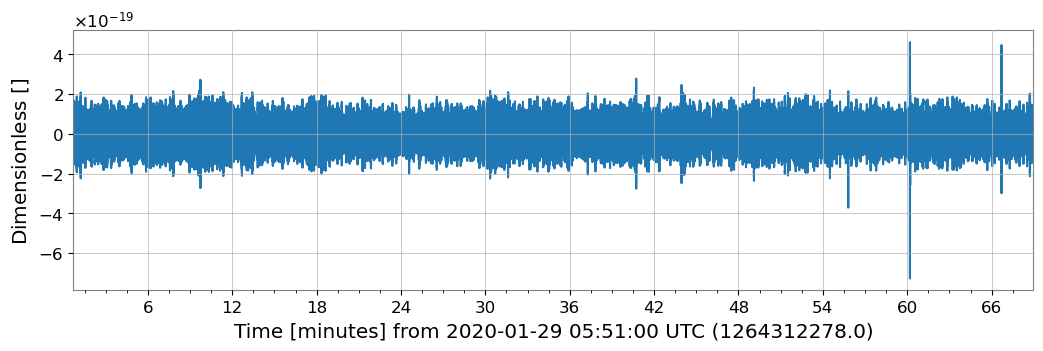

In [3]:
figure = data.plot()

## Baixando dados¶

[GWpy](https://gwpy.github.io/) pode ser usado para baixar um conjunto de dados em torno de um horário GPS graças à classe-método [fetch_open_data](https://gwpy.github.io/docs/stable/timeseries/opendata/#timeseries-fetch-open-data).

Este método oferece mais flexibilidade em comparação com o download de arquivos para posterior leitura dos dados neles contidos, pois permite baixar exatamente os dados desejados, sem a necessidade de alternar entre vários arquivos.

Por exemplo, vamos baixar os dados referentes aos primeiros 15 segundos:

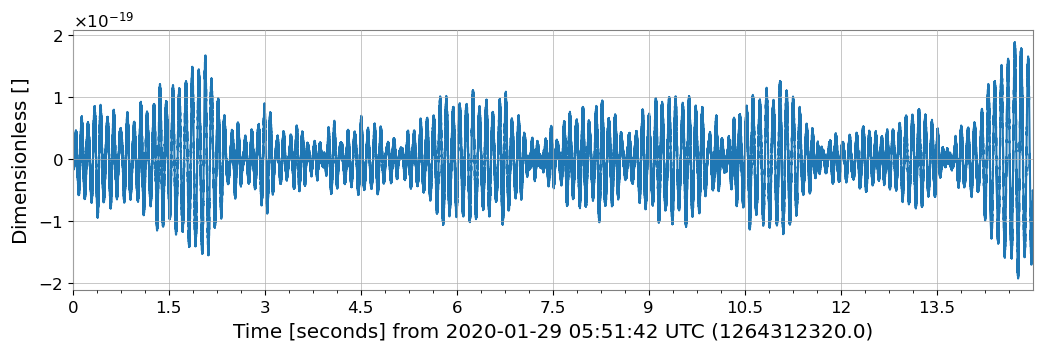

In [4]:
start = 1264312320

data_15s = TimeSeries.fetch_open_data('H1', start, start + 15)
figure_data_15s = data_15s.plot()

Além disso, você pode baixar dados sobre um evento específico:

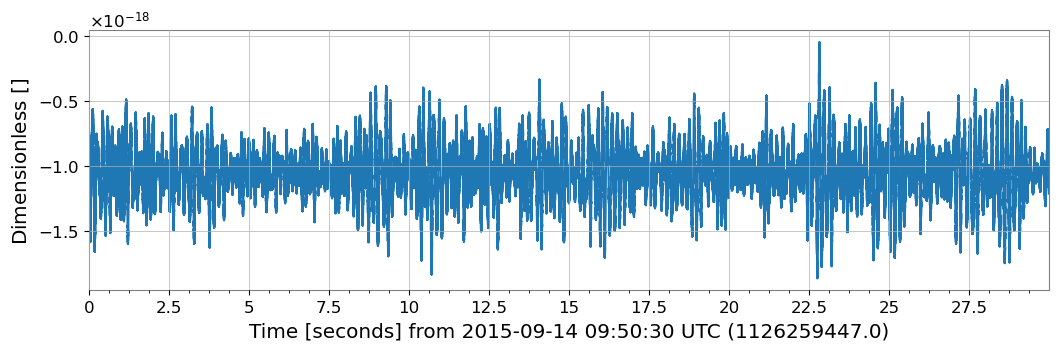

In [5]:
from gwosc.datasets import event_gps

event_gps   = event_gps("GW150914")
event_start = int(event_gps) - 15
event_end   = int(event_gps) + 15

event_data = TimeSeries.fetch_open_data('L1', event_start, event_end)
event_figure = event_data.plot()

O pacote [gwosc](https://gwosc.readthedocs.io/en/stable/) é uma interface de baixo nível para o site GWOSC que é usada por [GWpy](https://gwpy.github.io/) para algumas operações.

### Manipulando [TimeSeries](https://gwpy.github.io/docs/stable/timeseries/)

[TimeSeries](https://gwpy.github.io/docs/stable/timeseries/) pode ser fatiado usando tempo, não apenas índices.

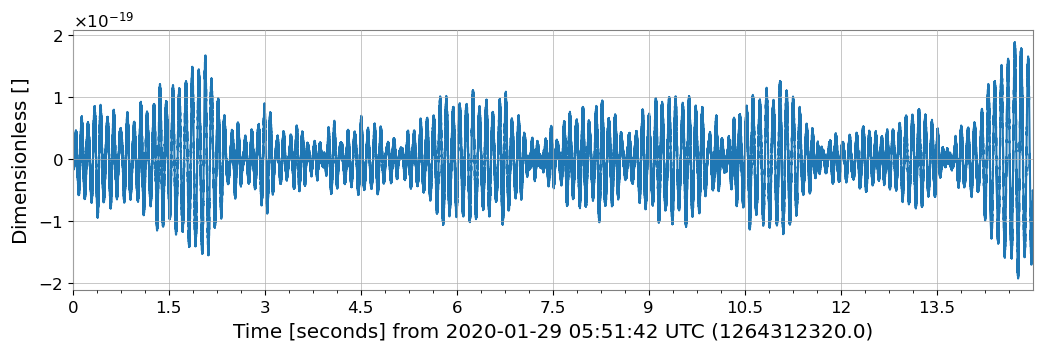

In [6]:
cropped_data = data.crop(start, start + 15)
cropped_figure = cropped_data.plot()

Como você pode ver, o eixo do tempo também está segmentado corretamente.

[TimeSeries](https://gwpy.github.io/docs/stable/timeseries/) objetos também contam com métodos avançados de estatística e processamento de sinais.
Leia mais [here](https://gwpy.github.io/docs/stable/examples/timeseries/).

## Qualidade de dados e segmentos

O acesso à qualidade dos dados é feito através da classe [StateVector](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector).

Vamos começar lendo as informações de qualidade dos dados do nosso arquivo com a classe-métod [read](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector.read):

In [7]:
from gwpy.timeseries import StateVector

state = StateVector.read(filename, format="hdf5.gwosc")
print(state)

StateVector([127, 127, 127, ..., 127, 127, 127]
            unit: dimensionless,
            t0: 1264312320.0 s,
            dt: 1.0 s,
            name: Data quality,
            channel: None,
            bits: Bits(0: data present
                        1: passes the cbc CAT1 test
                        2: passes cbc CAT2 test
                        3: passes cbc CAT3 test
                        4: passes burst CAT1 test
                        5: passes burst CAT2 test
                        6: passes burst CAT3 test,
                        channel=None,
                        epoch=1264312320.0))


Você reconhecerá a representação da máscara de bits que vimos no [passo 3](<03 - Working with Data Quality.ipynb>).
Observe que os nomes dos canais são extraídos de suas descrições.

Vamos traçar isso no gráfico.

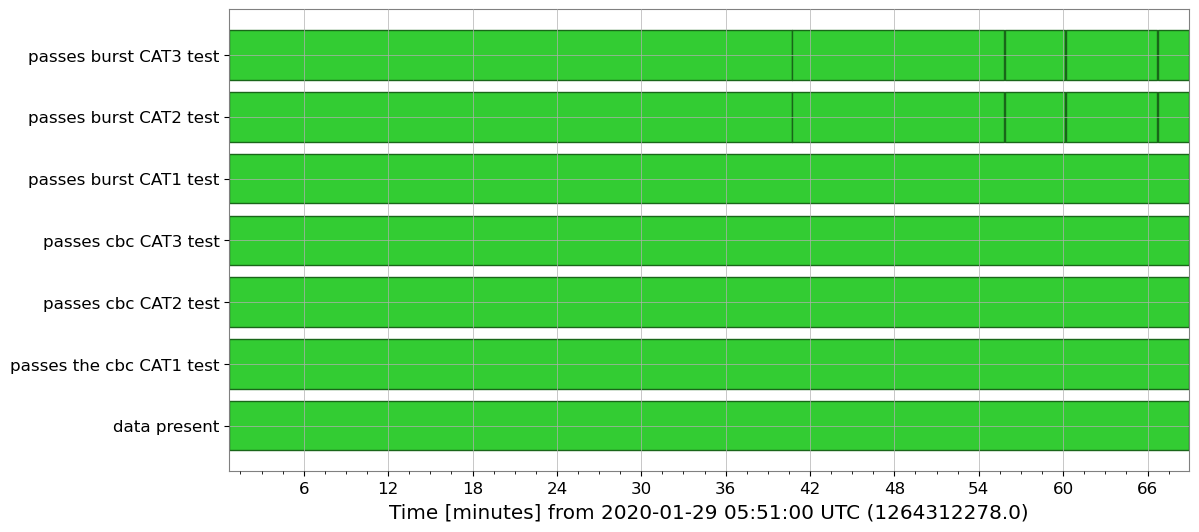

In [8]:
figure_state = state.plot()

Vamos tentar converter isso em uma lista de segmentos, como fizemos no [passo 3](<03 - Working with Data Quality.ipynb>).
Para isso, utilizamos primeiro o método [to_dqflags](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector.to_dqflags) girar o objeto [StateVector](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector) para um [DataQualityFlag](https://gwpy.github.io/docs/stable/api/gwpy.segments.DataQualityFlag/#gwpy.segments.DataQualityFlag), um objeto que representa os segmentos em cada categoria.

In [9]:
flags = state.to_dqflags()
print(flags)

DataQualityDict({'data present': <DataQualityFlag('data present',
                 known=[[1264312320.0 ... 1264316416.0)]
                 active=[[1264312320.0 ... 1264316416.0)]
                 description=None)>, 'passes the cbc CAT1 test': <DataQualityFlag('passes the cbc CAT1 test',
                 known=[[1264312320.0 ... 1264316416.0)]
                 active=[[1264312320.0 ... 1264316416.0)]
                 description=None)>, 'passes cbc CAT2 test': <DataQualityFlag('passes cbc CAT2 test',
                 known=[[1264312320.0 ... 1264316416.0)]
                 active=[[1264312320.0 ... 1264316416.0)]
                 description=None)>, 'passes cbc CAT3 test': <DataQualityFlag('passes cbc CAT3 test',
                 known=[[1264312320.0 ... 1264316416.0)]
                 active=[[1264312320.0 ... 1264316416.0)]
                 description=None)>, 'passes burst CAT1 test': <DataQualityFlag('passes burst CAT1 test',
                 known=[[1264312320.0 ... 1264316416.0

As categorias podem ser combinadas utilizando operações lógicas.
Assim, para encontrar dados em que ambas as categorias `DATA` e `BURST_CAT2` estejam presentes, podemos proceder da seguinte forma.

In [10]:
mask = flags['data present'] & flags['passes burst CAT2 test']
print(mask.active)

[[1264312320.0 ... 1264314720.0)
 [1264314723.0 ... 1264315625.0)
 [1264315628.0 ... 1264315888.0)
 [1264315891.0 ... 1264316279.0)
 [1264316282.0 ... 1264316416.0)]


Esta é a mesma lista de segmentos do [passo 3](<03 - Working with Data Quality.ipynb>).

Agora podemos traçar os primeiros segundos de cada segmento.

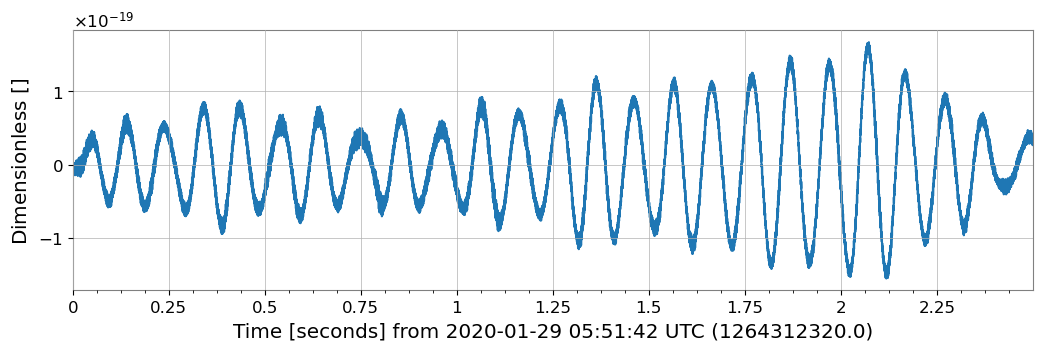

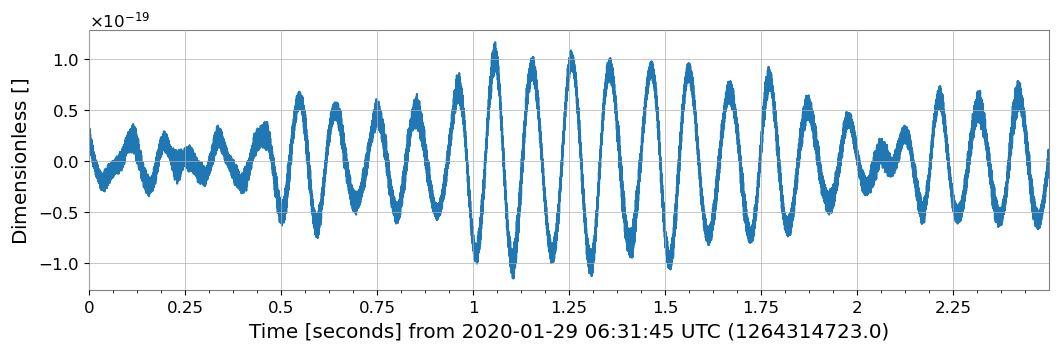

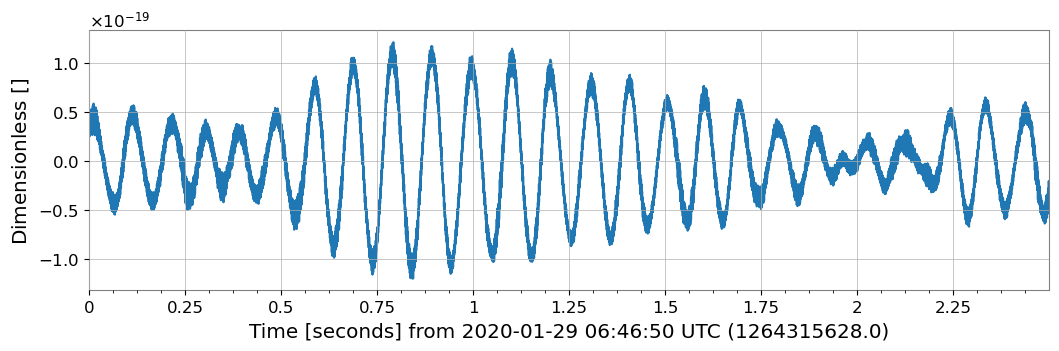

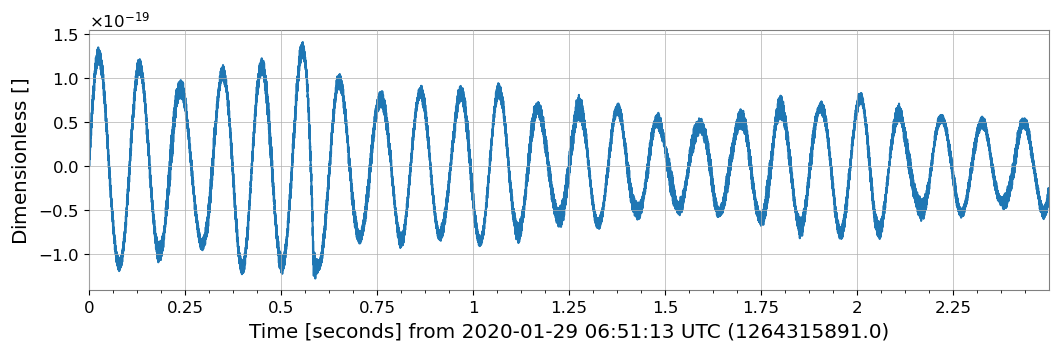

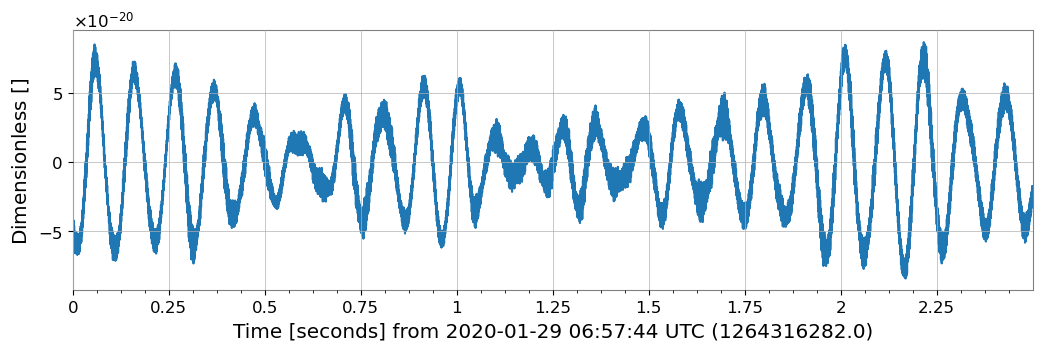

In [11]:
for (begin, end) in mask.active:
    sub = data.crop(begin, begin + 2.5)
    sub.plot()

Assim como [TimeSeries](https://gwpy.github.io/docs/stable/timeseries/), a classe [StateVector](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector)  também tem um método [fetch_open_data](https://gwpy.github.io/docs/stable/api/gwpy.timeseries.StateVector/#gwpy.timeseries.StateVector.fetch_open_data) para baixar exatamente os dados de que você precisa.

## Como ir além?

[GWpy](https://gwpy.github.io/) Possui muito mais funções e uma documentação bastante completa.
Dê uma olhada.[here](https://gwpy.github.io/docs/stable/).

Em particular, dê uma olhada na classe [FrequencySeries](https://gwpy.github.io/docs/stable/spectrum/) que é muito útil para trabalhar no domínico das frequências.

## What's next ?

Congratulations, you have completed the first steps of working with GW data !

To continue your journey, we recommend you take a look at the [GWOSC Learning Path](https://gwosc.org/path/).
To explore some events, you might be interested in our [Gravitational Wave Quickview tutorial](https://github.com/gwosc-tutorial/quickview).
And finally, you can participate in our annual [GW Open Data Workshops](https://gwosc.org/workshops/).